In [ ]:
import numpy as np


def entropy(y):
    """calculated the entropy of a classification target from this code"""
    if len(y) == 0:
        return 0.0

    _, counts = np.unique(y, return_counts=True)
    probab = counts / len(y)
    return -np.sum(probab * np.log2(probab))


def gini_impurity(y):
    if len(y) == 0:
        return 0.0

    _, counts = np.unique(y, return_counts=True)
    probab = counts / len(y)
    return 1.0 - np.sum(probab**2)


y = np.array([0, 0, 0, 1, 1, 1])

print("entropy:", entropy(y))
print("Gini:", gini_impurity(y))

entropy: 1.0
Gini: 0.5


In [ ]:
def information_gain(y, left_indices, right_indices):
    """Calculate entropy_based information gain for a split"""
    parent_entropy = entropy(y)
    n = len(y)
    left_y = y[left_indices]
    right_y = y[right_indices]
    weighted_child_entropy = len(left_y) / n * entropy(left_y) + len(
        right_y
    ) / n * entropy(right_y)

    return parent_entropy - weighted_child_entropy


x = np.array([1, 2, 3, 4, 5, 6])
y = np.array([0, 0, 0, 1, 1, 1])

In [ ]:
left_indices = x <= 3.5
right_indices = x > 3.5

gain = information_gain(y, left_indices, right_indices)

print("Information gain:", gain)

Information gain: 1.0


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

In [ ]:
data = load_breast_cancer()
x = pd.DataFrame(data.data, columns=data.feature_names)
y = pd.DataFrame(data.target, columns=["target"])
print(x.shape)
print(y.shape)
print(x.columns.tolist())
print(data.target_names)
print(x.head())
print(y.value_counts().rename(index={0: "malignant", 1: "benign"}))

(569, 30)
(569, 1)
['mean radius', 'mean texture', 'mean perimeter', 'mean area', 'mean smoothness', 'mean compactness', 'mean concavity', 'mean concave points', 'mean symmetry', 'mean fractal dimension', 'radius error', 'texture error', 'perimeter error', 'area error', 'smoothness error', 'compactness error', 'concavity error', 'concave points error', 'symmetry error', 'fractal dimension error', 'worst radius', 'worst texture', 'worst perimeter', 'worst area', 'worst smoothness', 'worst compactness', 'worst concavity', 'worst concave points', 'worst symmetry', 'worst fractal dimension']
['malignant' 'benign']
   mean radius  mean texture  ...  worst symmetry  worst fractal dimension
0        17.99         10.38  ...          0.4601                  0.11890
1        20.57         17.77  ...          0.2750                  0.08902
2        19.69         21.25  ...          0.3613                  0.08758
3        11.42         20.38  ...          0.6638                  0.17300
4      

In [ ]:
x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.2, random_state=2, stratify=y
)
x_train.shape

(455, 30)

In [ ]:
model = DecisionTreeClassifier(criterion="gini", max_depth=None, random_state=42)
model.fit(x_train, y_train)
y_pred = model.predict(x_test)
print("accuracy_score:", accuracy_score(y_test, y_pred))

accuracy_score: 0.956140350877193


In [ ]:
y_train_pred = model.predict(x_train)
y_test_pred = model.predict(x_test)

print("Training accuracy:", round(accuracy_score(y_train, y_train_pred), 4))

print("Testing accuracy:", round(accuracy_score(y_test, y_test_pred), 4))

print("\nClassification report:")
print(classification_report(y_test, y_test_pred, target_names=data.target_names))

print("Confusion matrix:")
print(confusion_matrix(y_test, y_test_pred))

Training accuracy: 1.0
Testing accuracy: 0.9561

Classification report:
              precision    recall  f1-score   support

   malignant       0.95      0.93      0.94        42
      benign       0.96      0.97      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114

Confusion matrix:
[[39  3]
 [ 2 70]]


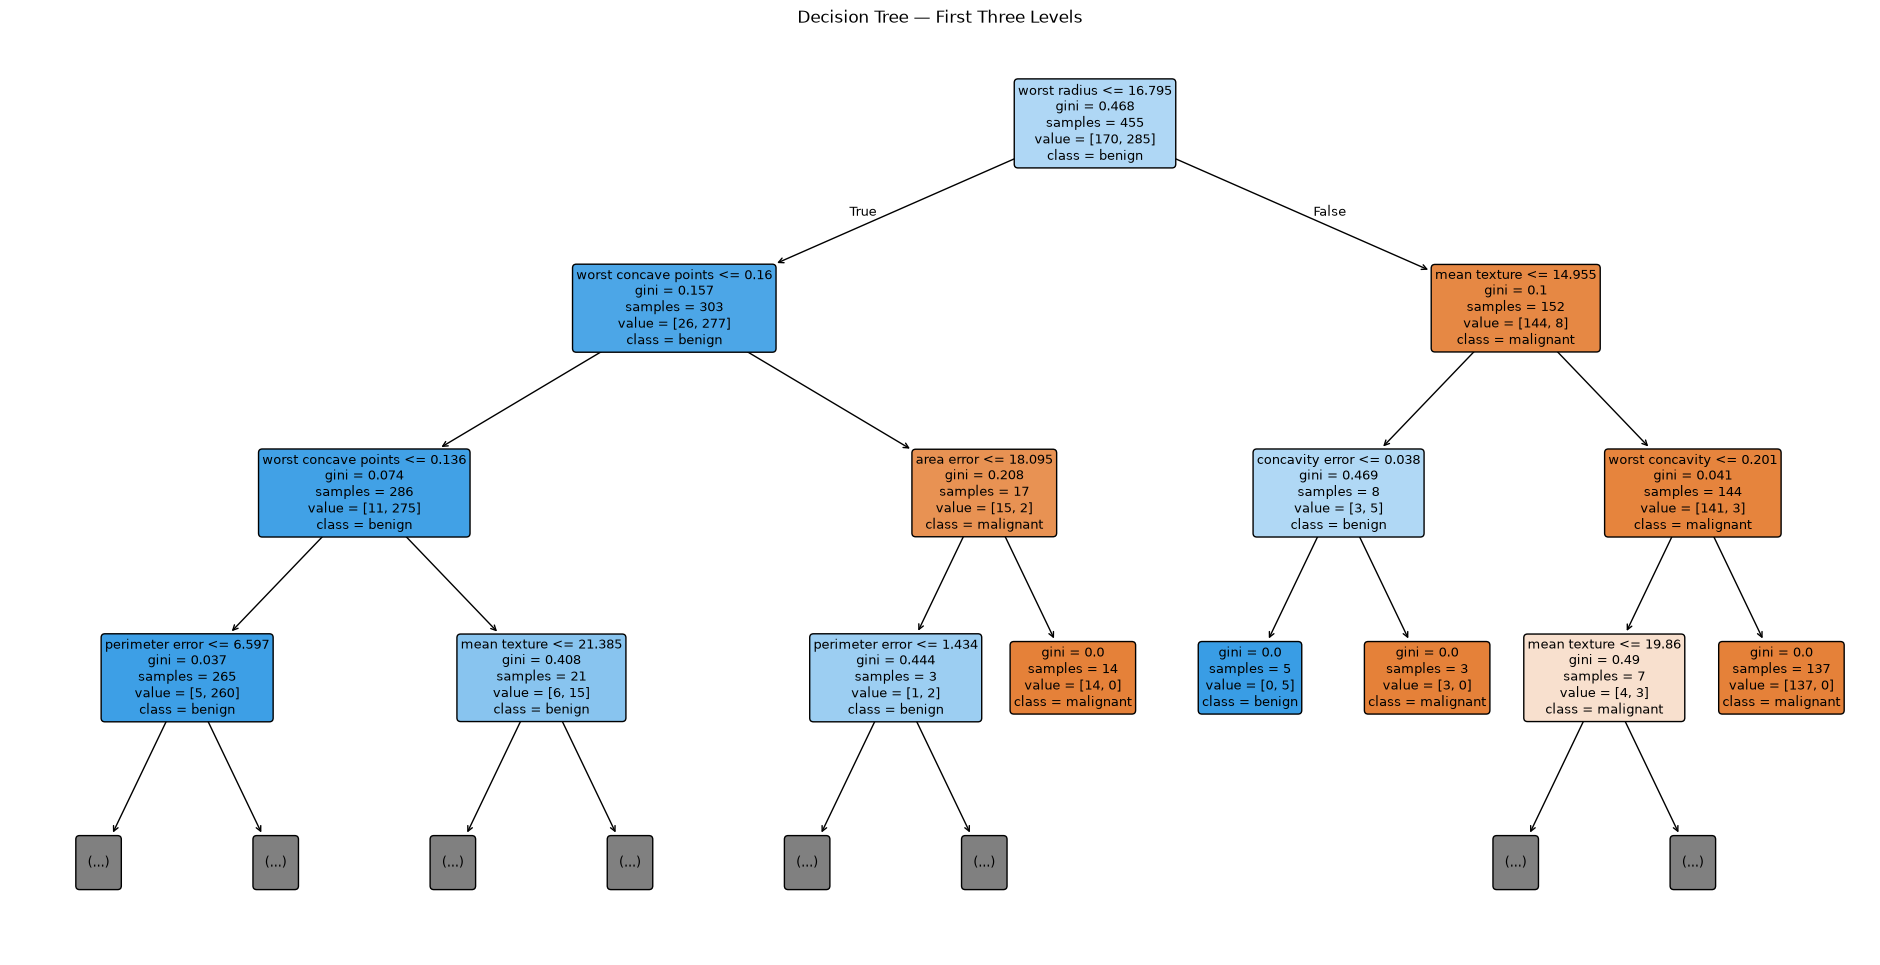

In [ ]:
plt.figure(figsize=(24, 12))

plot_tree(
    model,
    feature_names=x.columns,
    class_names=data.target_names,
    filled=True,
    rounded=True,
    max_depth=3,
    fontsize=9,
)

plt.title("Decision Tree — First Three Levels")
plt.show()

In [26]:

import optuna
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score


def objective(trial):
    criterion = trial.suggest_categorical(
        'criterion', ['gini', 'entropy', 'log_loss']
    )

    max_depth = trial.suggest_categorical(
        'max_depth', [None, 3, 5, 7, 10, 15, 20]
    )

    min_samples_split = trial.suggest_int(
        'min_samples_split', 2, 20
    )

    min_samples_leaf = trial.suggest_int(
        'min_samples_leaf', 1, 10
    )

    max_features = trial.suggest_categorical(
        'max_features', [None, 'sqrt', 'log2']
    )

    model = DecisionTreeClassifier(
        criterion=criterion,
        max_depth=max_depth,
        min_samples_leaf=min_samples_leaf,
        min_samples_split=min_samples_split,
        max_features=max_features,
        random_state=42
    )

    cv = StratifiedKFold(
        n_splits=5,
        shuffle=True,
        random_state=42
    )

    score = cross_val_score(
        model,
        x_train,
        y_train,
        cv=cv,
        scoring='accuracy',
        n_jobs=-1
    )

    return score.mean()


In [27]:
study = optuna.create_study(
    direction="maximize", sampler=optuna.samplers.TPESampler(seed=42)
)
study.optimize(objective, n_trials=30, show_progress_bar=True)
print(study.best_value)
print(study.best_params)

[I 2026-10-23 22:37:08,790] A new study created in memory with name: no-name-0089b938-7689-4ec5-976d-4e052dfdb590


  0%|          | 0/30 [00:00<?, ?it/s]

[I 2026-10-23 22:37:14,798] Trial 0 finished with value: 0.9164835164835164 and parameters: {'criterion': 'entropy', 'max_depth': 10, 'min_samples_split': 2, 'min_samples_leaf': 10, 'max_features': None}. Best is trial 0 with value: 0.9164835164835164.
[I 2026-10-23 22:37:17,195] Trial 1 finished with value: 0.9208791208791208 and parameters: {'criterion': 'log_loss', 'max_depth': 5, 'min_samples_split': 16, 'min_samples_leaf': 2, 'max_features': 'sqrt'}. Best is trial 1 with value: 0.9208791208791208.
[I 2026-10-23 22:37:17,262] Trial 2 finished with value: 0.9208791208791208 and parameters: {'criterion': 'gini', 'max_depth': 3, 'min_samples_split': 4, 'min_samples_leaf': 5, 'max_features': 'sqrt'}. Best is trial 1 with value: 0.9208791208791208.
[I 2026-10-23 22:37:17,303] Trial 3 finished with value: 0.9098901098901099 and parameters: {'criterion': 'gini', 'max_depth': 5, 'min_samples_split': 19, 'min_samples_leaf': 1, 'max_features': 'log2'}. Best is trial 1 with value: 0.920879120